In [147]:
#####################################################
# imports
#####################################################

import numpy as np
import os
import pandas as pd
import seaborn as sns
import random

# Note that suppressing warnings using the "warnings" package does not work when using multiprocessing
# see https://github.com/scikit-learn/scikit-learn/issues/12939
import warnings

warnings.filterwarnings('ignore')

# This works for most things, but obviously removes potentially important warnings
os.environ['PYTHONWARNINGS'] = 'ignore'
# This redirects all output to standard error into a file, which at least makes the output clean
# import sys
# sys.stderr = open('log.txt', 'w')

from dotenv import load_dotenv

from sklearn import set_config

import matplotlib.colors as colors
import matplotlib.pyplot as plt

from ms_demographics_table import get_characteristic_table

# make transform operations return dataframes
set_config(transform_output='pandas')

# remove dtype from printing
np.set_printoptions(legacy='1.25')


In [148]:
#####################################################
# Experimental Parameters
#
#####################################################
# TODO this should be a config object that is saved with the results

# get variables from .env, e.g. DATA_DIR
load_dotenv()

data_version = os.getenv('DATA_VERSION', 'V7.3')
data_dir = os.getenv('DATA_DIR', '../Dataset/')
data_dir = data_dir + '/' + data_version + '/'

visit_var = 'visit.number'
edss_var = 'edfscr1l'

if data_version == 'V7.3':
    data_file = 'MS_dataset_v.7.3.csv'
    dmo_data_dir_suffix = ' Aggregated DMO Data_V7.3'
    dmo_data_file_suffix = '-weekly_agg_all-21-01-2026.csv'
    participant_id_var = 'local.participant'
    dmo_participant_id_var = 'participant_id'
    dmo_visit_var = 'visit_type'
elif data_version == 'V1.0.0': # first public release from Zenodo
    data_file = 'MS_dataset.csv'
    dmo_data_dir_suffix = '_Aggregated_DMO_Data'
    dmo_data_file_suffix = '-weekly_agg_all.csv'
    participant_id_var = 'participantid'
    dmo_participant_id_var = 'participantid'
    dmo_visit_var = 'visit_number'
else:
    raise ValueError('Data version not supported:', data_version)

def min_increase_for_progression(edss_score):
    return 1.0 if edss_score <= 5.5 else 0.5


# whether to choose the 'first', 'last' or 'random' valid progression or non-progression time point for a participant
progression_select = 'first'

# both recall_macro and balanced_accuracy are defined as the average of recall obtained on each class.
scoring = 'recall_macro'

# how progression is calculated
# Constraint that the minimum previous EDSS score is 3.0, given that was the minimum used for recruitment.
edss_group_scores = {
    'G0': [3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0],
    'G1': [3.0, 3.5, 4.0],
    'G2': [4.5, 5.0, 5.5],
    'G3': [6.0, 6.5, 7.0]
}
edss_group_names = edss_group_scores.keys()
edss_group_type = 'G0'

min_progression_points = 2  # needs to be min 2 to have confirmed progression
# row type is one of: 'participant', 'progression', 'transition'
# 'progression' was an experiment to see if it would produce something interesting, which it doesn't seem to do
data_row_type = 'participant'

drop_DMO_features = False
drop_non_DMO_features = False
drop_features_as_predictors = [edss_var]

# This is the order in which the models will be reported
model_names_ordered = ['SVM', 'MLP', 'KNN', 'LR', 'DT', 'RF', 'XGB']
# List of ML model types to include in the experiment, in the order they are processed
model_types = ['SVM', 'KNN', 'LR', 'DT', 'RF', 'XGB', 'MLP']
# model_types = ['KNN', 'DT']

# default values for cross validation
n_splits = 5
n_repeats = 20

# Feature Selection (FS) parameters
feature_selection_type = 'fixed'  # should be be sfs2, can be 'fixed' if already generated
show_feature_analysis = False
show_mi_feature_selection = False
show_cluster_feature_selection = False
show_pca_feature_selection = False
show_rfe_feature_selection = False
show_sfs_feature_selection = False
show_feature_agglomeration = False
show_redundant_features = False
# number of parallel jobs to run
# if n_jobs <0, the actual n_jobs is 1 + (n_cpus + n_jobs)
fs_n_jobs = -2

# Mutual Information minimum selection threshold
mi_threshold = 0.0

# Sequential Feature Selection (SFS) features
# see https://rasbt.github.io/mlxtend/user_guide/feature_selection/SequentialFeatureSelector/
sfs_verbose = 1
sfs_forward = True
sfs_floating = True
# If features are set to <1 then it will use 1 for min and the number of features for max
# Setting max to less than number of features reduces compute time, but if floating is true max should be greater than the desired number of features
sfs_min_features = 1
sfs_max_features = 15  #-1
# SFS with Hyper-Parameter Tuning
sfs_do_hpt = False
sfs_hpt_n_iter = 1  # set to 2 for BayesSearchCV as higher values produce (erratic) worse results
sfs_hpt_verbose = 0
sfs_hpt_n_jobs = 5
# sfs hpt values for cross validation
sfs_hpt_n_repeats = 1

# SFS2 does sfs with multiple restarts
# The parameters allow you to reduce the number of repeats and max_k, to speed up processing.
sfs2_verbose = 0
sfs2_restarts = 20
sfs2_repeats = 5
sfs2_max_k = 10

# under/over sampling
do_data_sampling = False

random_state = 42
random.seed(random_state)

# hyper parameter tuning values
do_hpt = False
model_hpt_type = {
    'SVM': 'grid',
    'MLP': 'bayes',
    'KNN': 'grid',
    'LR': 'grid',
    'DT': 'grid',
    'RF': 'grid',
    'XGB': 'bayes'
}

hpt_n_jobs = -2
hpt_n_iter = 20
hpt_verbose = 0

show_data_distributions = False

In [149]:
# TODO save the config and results for each experiment in separate directory
# where to save figures:
fig_save_dir = '../output/all_features/'
os.makedirs(fig_save_dir, exist_ok=True)


In [150]:
#####################################################
# Load data
#
#####################################################

# read in main MS dataset
data_file_path = data_dir + data_file
all_data = pd.read_csv(data_file_path)
all_data[visit_var] = all_data[visit_var].str.upper()  # for consistency with filenames
# convert all column names to lower case for consistency between versions
all_data.columns = all_data.columns.str.lower()

# get participant demographics
demo_data = all_data.copy()
demo_data = demo_data[demo_data[visit_var] == 'T1']

# after getting table values, just crop to the necessary columns
cols_from_dataset = [participant_id_var, edss_var, visit_var,
                     'age', 'gender', 'mstypeonset', 'mstypediag', 'visit.date']
data = all_data[cols_from_dataset]

# forward fill within groups to ensure no leakage of demographics between participants
cols_from_dataset = [col for col in cols_from_dataset if col in ['age', 'gender', 'mstypeonset', 'mstypediag']]
for col in cols_from_dataset:
    data[col] = data.groupby(participant_id_var)[col].ffill()

# we need to get the time difference and convert from timedelta to something that the ML models can use - probably unix time
data['time_since_diag'] = (pd.to_datetime(data['visit.date']) - pd.to_datetime(data['mstypediag'])).dt.total_seconds()
data['time_since_onset'] = (pd.to_datetime(data['visit.date']) - pd.to_datetime(data['mstypeonset'])).dt.total_seconds()

# drop cols used for calculation
data = data.drop(['mstypeonset', 'mstypediag', 'visit.date'], axis=1)

# convert gender to 0 and 1
data['gender'] = data['gender'].map({'Male': 0, 'Female': 1})

# print(f'Column NaN counts out of {len(data)} rows')
# print(data.isna().sum())
print(f'Nan counts at each timepoint')
g = data.groupby(visit_var)
print(g.count().rsub(g.size(), axis=0))

# drop rows with no EDSS score
count_before = data[participant_id_var].nunique()
print(f"Dropping {sum(data[edss_var].isna())} rows with no EDSS score...")
data = data.dropna(subset=[edss_var])
print(
    f'Dropping rows results in {count_before - data[participant_id_var].nunique()} participants excluded with no EDSS scores...')

print(f'Nan counts at each timepoint')
g = data.groupby(visit_var)
print(g.count().rsub(g.size(), axis=0))

# Crop down to just the necessary columns
data = data.sort_values(by=[participant_id_var, visit_var])


Nan counts at each timepoint
              local.participant  edfscr1l  age  gender  time_since_diag  \
visit.number                                                              
T1                            0         4    0       0                2   
T2                            0       105    0       0               62   
T3                            0       121    0       0               87   
T4                            0       147    0       0              107   
T5                            0       112    0       0               71   

              time_since_onset  
visit.number                    
T1                           2  
T2                          62  
T3                          87  
T4                         107  
T5                          71  
Dropping 489 rows with no EDSS score...
Dropping rows results in 0 participants excluded with no EDSS scores...
Nan counts at each timepoint
              local.participant  edfscr1l  age  gender  time_since_diag  

In [152]:
#####################################################
# Functions to calculate participant-based progression
#
#####################################################

timepoints = ['T1', 'T2', 'T3', 'T4', 'T5']


def calc_progression(tp_scores, min_score, return_all=False, select=progression_select):
    progressions = []
    non_progressions = []

    for i, tp0 in enumerate(timepoints):
        if i == len(tp_scores) - min_progression_points:
            break
        if tp_scores[tp0] >= min_score:
            valid_future_points = []
            for j in range(i + 1, len(timepoints)):
                if not np.isnan(tp_scores.iloc[j]):
                    valid_future_points.append(tp_scores.iloc[j])
            # if there are at least min_progression_points future non-null timepoints, then this is valid
            if len(valid_future_points) >= min_progression_points:
                min_progression = min_increase_for_progression(tp_scores[tp0])
                is_progression = True
                # if any of the consecutive future timepoint scores is
                # less than required for progression, this is not progression
                for j in range(min_progression_points):
                    if valid_future_points[j] - tp_scores[tp0] < min_progression:
                        is_progression = False
                        break

                if is_progression:
                    progressions.append({'timepoint': tp0, 'next_edss': valid_future_points[0], 'progression': 1})
                else:
                    non_progressions.append({'timepoint': tp0, 'next_edss': valid_future_points[0], 'progression': 0})
            else:  # if no valid future timepoints
                break

    if return_all:
        return progressions, non_progressions
    # if there are no valid values
    if len(progressions) == 0 and len(non_progressions) == 0:
        return {'timepoint': None, 'next_edss': None, 'progression': None}

    # return progression if they exist, otherwise non_progression
    result = progressions if len(progressions) > 0 else non_progressions
    if len(result) == 1:
        return result[0]
    match select:
        case 'first':
            return result[0]
        case 'last':
            return result[-1]
        case _:  # random
            return result[random.randint(0, len(result) - 1)]



602 participants read from file...
15 participants excluded with missing DMOs at timepoints T1, T2 and T3.
11 participants excluded as have T1-3 EDSS scores are all NaN...
0 participants excluded as have T1-3 EDSS scores > threshold (7.0)...
Participants excluded as they have no valid timepoints
visit.number        T1  T2   T3  T4  T5 timepoint  next_edss  progression
local.participant                                                        
10377              4.0 NaN  NaN NaN NaN       NaN        NaN          NaN
10390              5.0 NaN  NaN NaN NaN       NaN        NaN          NaN
10398              4.0 NaN  NaN NaN NaN       NaN        NaN          NaN
10410              6.0 NaN  NaN NaN NaN       NaN        NaN          NaN
10420              4.5 NaN  NaN NaN NaN       NaN        NaN          NaN
...                ...  ..  ...  ..  ..       ...        ...          ...
25230              6.5 NaN  NaN NaN NaN       NaN        NaN          NaN
25231              4.0 NaN  NaN NaN N

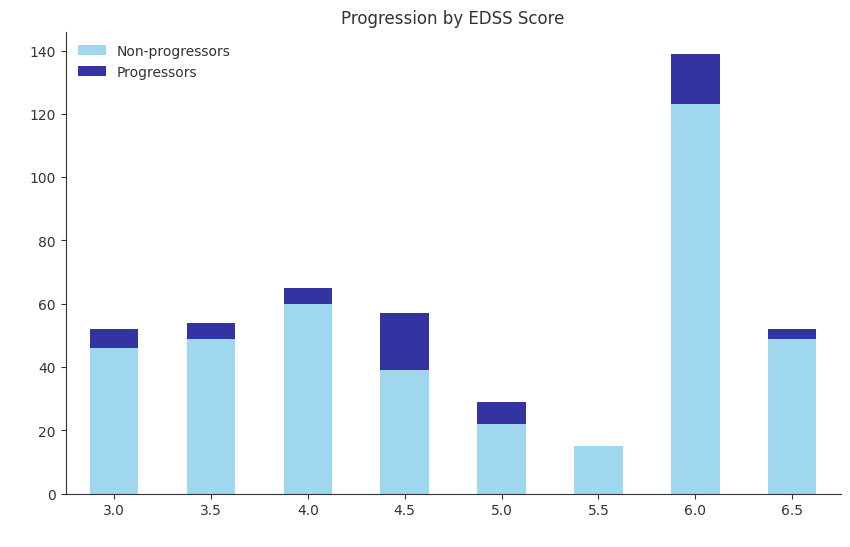

In [153]:
#####################################################
# Calculate Participant-based Progression
#
#####################################################

# Add the DMO data so that timepoints with missing DMOs are not considered in the calculations
dfs_list = []
for timepoint in ['T1', 'T2', 'T3']:
    feature_file_path = data_dir + f'/{timepoint}{dmo_data_dir_suffix}/cvs-{timepoint}{dmo_data_file_suffix}'
    temp_df = pd.read_csv(feature_file_path)
    dfs_list.append(temp_df)

dmo_data = pd.concat(dfs_list, ignore_index=True)
# convert all column names to lower case for consistency between versions
dmo_data.columns = dmo_data.columns.str.lower()
dmo_data[dmo_visit_var] = dmo_data[dmo_visit_var].str.upper()  # for consistency with filenames

merged_data = pd.merge(data, dmo_data, left_on=[participant_id_var, visit_var],
                       right_on=[dmo_participant_id_var, dmo_visit_var], how='left')

if not dmo_participant_id_var == participant_id_var:
    merged_data = merged_data.drop([dmo_participant_id_var], axis=1)
merged_data = merged_data.drop([dmo_visit_var], axis=1)

# print(f'Column NaN counts out of {len(merged_data)} T1, T2, T3 rows')
# print(merged_data[merged_data[visit_var].isin({'T1', 'T2', 'T3'})].isna().sum())

# drop T1, T2, and T3 rows if they contain nan, which will be due to missing DMOs
count_before = merged_data[participant_id_var].nunique()
print(f'{count_before} participants read from file...')

# get indices of rows with any nan values
nan_indices = merged_data.index[merged_data.isna().any(axis=1)]
# get indices of rows with T1, T2 or T3 values
timepoint_indices = merged_data.index[merged_data[visit_var].isin({'T1', 'T2', 'T3'})]
# Get intersection of T1, T2, T3 rows with rows containing any nan
intersection = nan_indices.intersection(timepoint_indices)
merged_data = merged_data.drop(intersection)
print(
    f'{count_before - merged_data[participant_id_var].nunique()} participants excluded with missing DMOs at timepoints T1, T2 and T3.')

participant_data = (merged_data[[participant_id_var, visit_var, edss_var]]
                    .pivot(index=participant_id_var, columns=visit_var, values=edss_var))

count_before = len(participant_data)
participant_data = participant_data[participant_data[['T1', 'T2', 'T3']].isna().sum(axis='columns') < 3]
print(
    f'{count_before - len(participant_data)} participants excluded as have T1-3 EDSS scores are all NaN...')

base_scores = edss_group_scores['G0']

count_before = len(participant_data)
participant_data = participant_data[participant_data[['T1', 'T2', 'T3']].le(base_scores[-1]).any(axis='columns')]
print(
    f'{count_before - len(participant_data)} participants excluded as have T1-3 EDSS scores > threshold ({base_scores[-1]})...')

# Add progression data with baseline timepoint, next_edss score after baseline, and whether baseline is followed by a confirmed progression (0,1)
participant_data[['timepoint', 'next_edss', 'progression']] = participant_data.apply(
    # threshold_progress_point, thresholds=base_scores, min_score=base_scores[0],
    calc_progression, min_score=base_scores[0],
    axis='columns', result_type='expand')

# calculate all progressions data
progression_data = []
for index, row in participant_data.iterrows():
    progressions, non_progressions = calc_progression(row, base_scores[0], return_all=True)
    for progression in progressions:
        progression_data.append([index, progression['timepoint'], progression['next_edss'], 1])
    for non_progression in non_progressions:
        progression_data.append([index, non_progression['timepoint'], non_progression['next_edss'], 0])
progression_data = pd.DataFrame(progression_data,
                                columns=[participant_id_var, 'timepoint', 'next_edss', 'progression'])

print('Participants excluded as they have no valid timepoints')
print(participant_data[participant_data['timepoint'].isna()])
# remove all participants who have insufficient (i.e. <3) timepoints
count_before = len(participant_data)
participant_data = participant_data.dropna(subset=['timepoint'])
print(f'{count_before - len(participant_data)} participants excluded who have insufficient (i.e. <3) timepoints...\n')

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print(participant_data[participant_data['progression'] == 1].head(100))

participant_data = participant_data.merge(merged_data, how='left',
                                          left_on=[participant_id_var, 'timepoint'],
                                          right_on=[participant_id_var, visit_var])
# remove processing columns
participant_data = participant_data.drop(['T1', 'T2', 'T3', 'T4', 'T5', 'timepoint'], axis=1)

progression_data = progression_data.merge(merged_data, how='left',
                                          left_on=[participant_id_var, 'timepoint'],
                                          right_on=[participant_id_var, visit_var])
# remove processing column
progression_data = progression_data.drop(['timepoint'], axis=1)

edss_group_participant_data = {}
for group in edss_group_scores.keys():
    edss_group_participant_data[group] = participant_data[participant_data[edss_var].isin(edss_group_scores[group])]
    print(f'EDSS group {group} size: {len(edss_group_participant_data[group])}')

    if not group == 'G0':
        print(f'Selecting EDSS scores for group {group}: {edss_group_scores[group]}')
        count_before = len(participant_data)
        count_after = len(edss_group_participant_data[group])
        print(f'Participants data: {count_before - count_after} participants excluded who are not in the group')

        participants_before = progression_data[participant_id_var].nunique()
        progressions_before = len(progression_data)
        progression_data = progression_data[progression_data[edss_var].isin(edss_group_scores[group])]
        print(
            f'Progression data: {participants_before - progression_data[participant_id_var].nunique()} participants excluded who are not in the group')
        print(f'Progression data: {progressions_before - len(progression_data)} progressions excluded from group')

    non_progressor_count = len(participant_data[participant_data['progression'] == 0])

    print(f'Number of included participants = {len(participant_data)}')
    print(f'Number of non-progressors = {non_progressor_count}')
    print(f'Number of progressors = {len(participant_data) - non_progressor_count}')

    print(pd.crosstab(participant_data['progression'], participant_data[edss_var]))

    ax = (pd.crosstab(participant_data[edss_var], participant_data['progression'])
          .plot(kind='bar',
                stacked=True,
                color=['skyblue', 'darkblue'],
                alpha=0.8,
                figsize=(10, 6)))

    plt.title('Progression by EDSS Score, Group ' + group)
    plt.xlabel('EDSS Score')
    plt.ylabel('Number of Participants')
    plt.xticks(rotation=0)
    plt.legend(['Non-progressors', 'Progressors'])
    plt.savefig('../output/progressors_' + group + '.png')
    plt.show()

get_characteristic_table(edss_group_participant_data, all_data,
                         edss_group_scores, participant_id_var)

#print(participant_data[participant_id_var].unique())


602 participants
2387 total participant timepoints rows
1785 rows after dropping NaN in next timepoint...
0 rows have missing EDSS values and will be dropped...


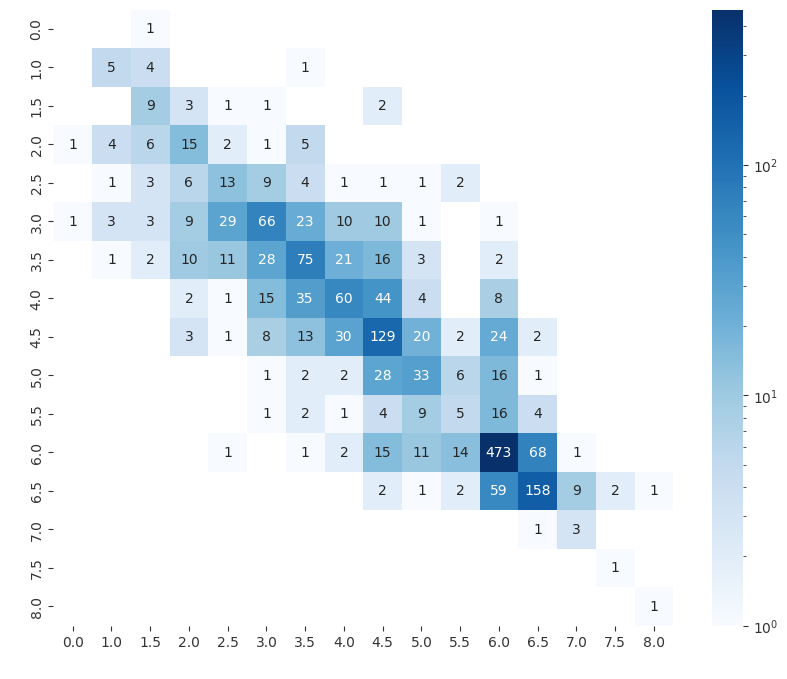

2 rows have a EDSS > 7.0 and will be dropped...
102 rows have a EDSS < 3.0 and will be dropped...
175 rows have missing DMOs and will be dropped...
We have 145 progressions across 132 subjects, out of a total of 1506 differences between timepoints across 519 subjects.


,local.participant,edfscr1l,visit.number,age,gender,time_since_diag,time_since_onset,next_edss,Next_Timepoint,progression,...,ws_30_avg_w,strlen_30_avg_w,cadence_30_avg_w,strdur_30_avg_w,ws_30_p90_w,cadence_30_p90_w,ws_30_var_w,strlen_30_var_w,wb_60_sum_w,n_days_w
20,10382,4.0,T1,60.0,1,1.256031e+09,1.271151e+09,6.0,T2,1,...,0.84,106.0,94.0,1.25,1.00,103.0,17.0,16.0,7.0,7.0
24,10383,6.0,T2,66.0,1,3.648082e+08,4.204498e+08,6.5,T3,1,...,0.62,98.0,77.0,1.19,0.68,80.0,20.0,23.0,1.0,6.0
28,10384,5.0,T3,57.0,1,5.663925e+08,5.687253e+08,6.0,T4,1,...,0.86,110.0,94.0,1.22,1.02,104.0,18.0,12.0,9.0,7.0
31,10385,4.5,T3,40.0,0,2.852436e+08,3.463284e+08,6.0,T4,1,...,0.96,116.0,98.0,1.16,1.12,109.0,18.0,14.0,10.0,7.0
49,10393,4.0,T1,44.0,1,2.423851e+08,8.152171e+08,5.0,T2,1,...,0.83,118.0,84.0,1.35,1.03,98.0,19.0,13.0,3.0,7.0


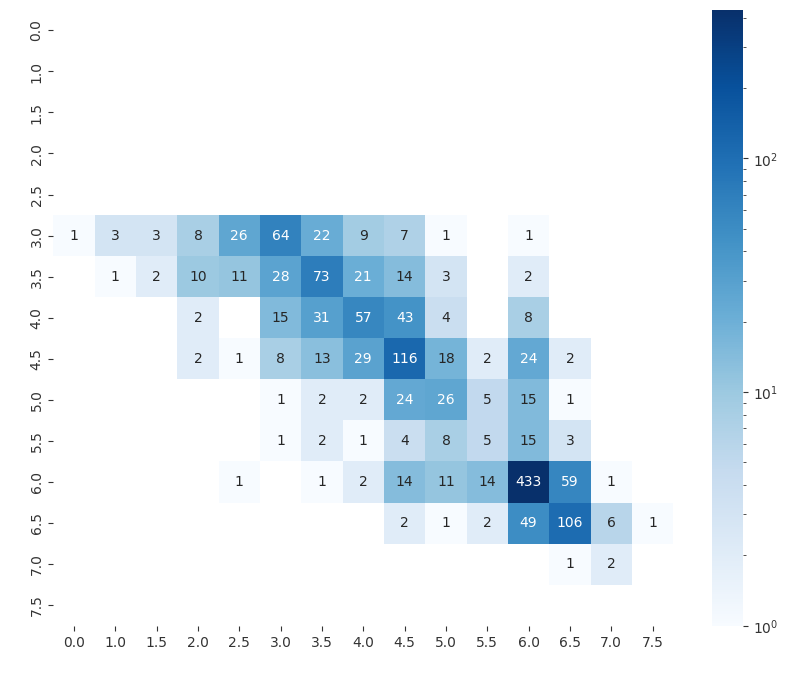

In [154]:
############################################################
# Calculate EDSS score consecutive timepoint transitions
#
############################################################

##

def show_transition_matrix(data, name):
    """
    Displays a matrix showing the current and next EDSS scores.

    :param data: the transition matrix to display
    :param name: the name of the transition matrix
    """
    # Create matrix of prev -> next EDSS scores
    prev_scores = data[edss_var].to_numpy().tolist()
    next_scores = data['next_edss'].to_numpy().tolist()

    # extract the unique scores
    scores = list(set(prev_scores).union(set(next_scores)))
    scores.sort()
    n_scores = len(scores)

    # Create transition matrix
    # Note some of these transitions will be for people with missing DMOs
    transition_matrix = pd.DataFrame(
        np.zeros((n_scores, n_scores), dtype=int),
        index=scores,
        columns=scores)

    for prev_score, next_score in zip(prev_scores, next_scores):
        transition_matrix.loc[prev_score, next_score] += 1

    # Pretty print transition matrix as heatmap
    plt.subplots(figsize=(10, 8))
    ax = plt.subplot(111)
    sns.heatmap(transition_matrix.values, annot=True, cmap='Blues', ax=ax, fmt='d', norm=colors.LogNorm())
    ax.set_ylabel('Previous Score')
    ax.set_xlabel('Next Score')
    ax.xaxis.set_ticklabels(scores)
    ax.yaxis.set_ticklabels(scores)
    plt.savefig('../output/' + name + '_' + edss_group_type + '.png')
    plt.show()


transition_data = data.copy()
print(f'{transition_data[participant_id_var].nunique()} participants')
print(f'{len(transition_data)} total participant timepoints rows')

# shift timepoints and EDSS to get next as columns
transition_data['next_edss'] = transition_data.groupby(participant_id_var)[edss_var].shift(-1)
transition_data['Next_Timepoint'] = transition_data.groupby(participant_id_var)[visit_var].shift(-1)

# drop lines that do not have a next timepoint
transition_data = transition_data.dropna(subset=['Next_Timepoint'])

# Data cleaning - will monitor number of rows throughout
print(f'{len(transition_data)} rows after dropping NaN in next timepoint...')

# get rid of participants where either current or next EDSS is missing
count_before = len(transition_data)
# drop lines that do not have a current or next EDSS score
transition_data = transition_data.dropna(subset=[edss_var, 'next_edss'])
print(f'{count_before - len(transition_data)} rows have missing EDSS values and will be dropped...')

# Show all transitions, regardless of whether they have DMO values
show_transition_matrix(transition_data, 'all_transitions')

# Exclude scores if they fall outside the acceptable range

# Exclude participants with current EDSS score >= threshold as they have already progressed:
count_before = len(transition_data)
high_prev_edss_mask = (transition_data[edss_var] > base_scores[-1])
print(f'{sum(high_prev_edss_mask)} rows have a EDSS > {base_scores[-1]} and will be dropped...')
transition_data = transition_data.drop(transition_data[high_prev_edss_mask].index)

# Exclude participants with EDSS score < min_prev_score as they are highly unlikely to progress, and may have different mobility patterns
count_before = len(transition_data)
low_prev_edss_mask = (transition_data[edss_var] < base_scores[0])
print(f'{sum(low_prev_edss_mask)} rows have a EDSS < {base_scores[0]} and will be dropped...')
transition_data = transition_data.drop(transition_data[low_prev_edss_mask].index)


def progression(row):
    return 1 if ((row[edss_var] > base_scores[0]) &
                 (row['next_edss'] >= base_scores[0]) &
                 ((row['next_edss'] - row[edss_var]) >= min_increase_for_progression(row[edss_var]))) else 0


# get progression label column
transition_data['progression'] = transition_data.apply(progression, axis=1)

# transitions = transition_data[progression_mask]  # all the data where a transition happens, just in case.
#display(transitions.head(10))

# now that we have a reduced dataset, loop through our weekly dmo aggregations and append the relevant ones to the dataframe

dfs_list = []
# we don't need DMOs where T5 is previous
for timepoint in ['T1', 'T2', 'T3', 'T4']:
    feature_file_path = data_dir + f'/{timepoint}{dmo_data_dir_suffix}/cvs-{timepoint}{dmo_data_file_suffix}'
    temp_df = pd.read_csv(feature_file_path)
    dfs_list.append(temp_df)

dmo_data = pd.concat(dfs_list, ignore_index=True)
# convert all column names to lower case for consistency between versions
dmo_data.columns = dmo_data.columns.str.lower()
dmo_data[dmo_visit_var] = dmo_data[dmo_visit_var].str.upper()  # for consistency with filenames

transition_data = pd.merge(transition_data, dmo_data, left_on=[participant_id_var, visit_var], right_on=[dmo_participant_id_var, dmo_visit_var], how='left')
if not dmo_participant_id_var == participant_id_var:
    transition_data = transition_data.drop([dmo_participant_id_var], axis=1)
transition_data = transition_data.drop([dmo_visit_var], axis=1)

# drop all remaining NAN rows, which will be due to missing DMOs
count_before = len(transition_data)
transition_data = transition_data.dropna()
print(f'{count_before - len(transition_data)} rows have missing DMOs and will be dropped...')

num_progressions = len(transition_data[transition_data['progression'] == 1])
unique_sub_progressions = len(transition_data[transition_data['progression'] == 1][participant_id_var].unique())
total_subs = transition_data[participant_id_var].nunique()

print(
    f'We have {num_progressions} progressions across {unique_sub_progressions} subjects, out of a total of {len(transition_data)} differences between timepoints across {total_subs} subjects.')

display(transition_data[transition_data['progression'] == 1].head(5))

# Show transitions that have DMOs
show_transition_matrix(transition_data, 'trimmed_transitions')

transition_data = transition_data.drop(['next_edss', 'Next_Timepoint'], axis=1)

# drop processing columns

In [155]:
#####################################################
# Prepare Training Data
#
#####################################################

if data_row_type == 'transition':
    data = transition_data
elif data_row_type == 'participant':
    data = participant_data
elif data_row_type == 'progression':
    data = progression_data
else:
    raise ValueError('Unknown data_row_type:', data_row_type)

# randomise the rows, to ensure there's no data ordering bias
index_names = data.index.names
if index_names[0] is None:
    index_names = ['index']
data = data.sample(frac=1, random_state=random_state).reset_index()
data.set_index(index_names, inplace=True)

# drop irrelevant or 'cheating' columns
y_data = data['progression']  #.reset_index(drop=True)  # can be data['progression'] or data['multiclass_progression']

labels_X_all = data

non_dmo_features = [edss_var, 'age', 'gender', 'time_since_diag', 'time_since_onset']
if drop_DMO_features:
    X_data = data[non_dmo_features]  #.reset_index(drop=True)
else:
    features_to_drop = [participant_id_var, visit_var, 'next_edss', 'progression']
    if drop_non_DMO_features:
        features_to_drop += non_dmo_features
    X_data = data.drop(features_to_drop, axis=1)

if drop_features_as_predictors:
    X_data = X_data.drop(drop_features_as_predictors, axis=1)

display(X_data.head(5))


,age,gender,time_since_diag,time_since_onset,wb_all_sum_w,walkdur_all_sum_w,wbsteps_all_sum_w,wbdur_all_avg_w,wbdur_all_p90_w,wbdur_all_var_w,...,ws_30_avg_w,strlen_30_avg_w,cadence_30_avg_w,strdur_30_avg_w,ws_30_p90_w,cadence_30_p90_w,ws_30_var_w,strlen_30_var_w,wb_60_sum_w,n_days_w
index,,,,,,,,,,,,,,,,,,,,,
225,55.0,1,662390707.0,820243507.0,298.0,76.0,7309.0,7.0,17.4,261.0,...,0.96,113.0,102.0,1.20,1.01,105.0,7.0,6.0,9.0,4.0
30,41.0,1,515749311.0,519378111.0,67.0,11.0,745.0,7.2,15.7,60.0,...,0.66,110.0,74.0,1.59,0.73,76.0,15.0,17.0,0.0,7.0
39,51.0,0,844332041.0,851071241.0,502.0,85.0,7431.0,7.3,19.0,93.0,...,0.78,111.0,84.0,1.26,0.95,90.0,18.0,15.0,2.0,7.0
222,50.0,1,621948569.0,711372569.0,391.0,75.0,6188.0,8.0,21.4,89.0,...,0.82,115.0,84.0,1.36,0.94,88.0,13.0,9.0,4.0,7.0
124,59.0,0,681380403.0,807610803.0,293.0,54.0,5091.0,8.4,20.7,82.0,...,0.88,107.0,95.0,1.18,1.15,108.0,29.0,20.0,1.0,7.0


In [156]:
#####################################################
# Data normalisation
#
#####################################################

# Data normalisation (Note the impact of this needs to be tested)
# e.g. StandardScaler, MinMaxScaler, RobustScaler
# If columns have different (e.g. skewed) distributions that may need different normalisations
# e.g. Log normalisation
# Note that StandardScaler is generally preferred,
# however combined with small data will hang SVC, while MinMaxScaler works

# moved scaler to inside function to prevent re-fitting

if show_data_distributions:
    for i, column in enumerate(X_data.columns):
        if X_data[column].dtype == 'float64':
            sns.displot(data=X_data, x=column, kind='kde')
        else:
            sns.displot(X_data, x=column)
